# Simulation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML
import matplotlib 
matplotlib.rc('font', family='serif')
matplotlib.rc('font', serif='STIXGeneral')
from cmcrameri import cm  #cmap=cm.lipari 
matplotlib.rcParams['animation.embed_limit'] = 50  # MB

### Global variables

In [2]:
matrix_height = 1600
matrix_width = 2550
radius = 50
Y, X = np.ogrid[:matrix_height, :matrix_width]

## Object & background 

In [3]:

def make_object_linear_3(t):
    '''creates a linear moving object'''
    Obj = np.zeros((matrix_height, matrix_width))
    # Object  (horizontal linear)
    x_move = int(centre_x)
    y_move = int(centre_y + amp_x * np.sin(t))
    
    moving_x.append(x_move)
    moving_y.append(y_move)
    
    Obj[y_move, x_move] = 1
    mask = (X - x_move)**2 + (Y - y_move)**2 <= radius**2
    Obj[mask] = 255

    x_move_2 = int(centre_x + amp_x * np.sin(t+2))
    y_move_2 = int(centre_y)
    
    moving_x_2.append(x_move_2)
    moving_y_2.append(y_move_2)
    
    Obj[y_move_2, x_move_2] = 1
    mask_2 = (X - x_move_2)**2 + (Y - y_move_2)**2 <= radius**2
    Obj[mask_2] = 255

    return Obj

### Animation

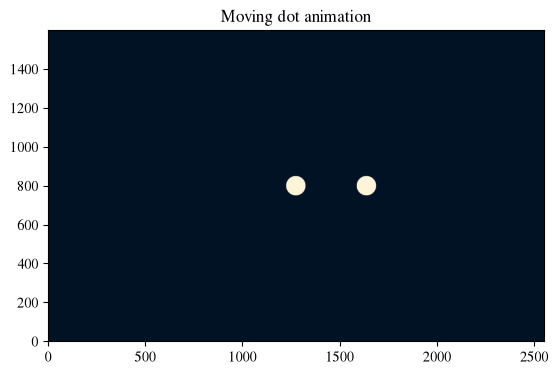

In [4]:
moving_x = []
moving_y = []

moving_x_2 = []
moving_y_2 = []

centre_x = matrix_width // 2
centre_y = matrix_height // 2
seperation = 300
amp_x = 400
amp_y = 400
noframes = 20
# animation
fig, ax = plt.subplots()
img = ax.imshow(make_object_linear_3(0), origin='lower',cmap=cm.lipari )
ax.set_title("Moving dot animation")


def animation_make_object_3(frame):
    '''inputs value for t to make each image frame'''
    t = 2 * np.pi * frame / noframes
    img.set_data(make_object_linear_3(t))
    return [img]

del moving_x[-1]
del moving_y[-1]


animation = FuncAnimation(fig, animation_make_object_3, frames=noframes, interval=100)


HTML(animation.to_jshtml())

In [17]:
# ==========================================
# Load CSV data
# ==========================================

import pandas as pd
from PIL import Image

data = pd.read_csv(
    "C:\\Users\\Student\\OneDrive - University of Exeter\\Desktop\\Imaging & tracking objects behind a scattering medium\\data\\cross correlation tracking\\shifts_cross_correlation_scale_5.75.csv",
    header=None
)
# Select the two shift columns
y_shifts = data.iloc[:, 0].to_numpy()
x_shifts = data.iloc[:, 1].to_numpy()

# Match the coordinates in your original plot
plot_x = x_shifts
plot_y = -y_shifts

# Show two new points per frame
points_per_frame = 2
data_frames = int(np.ceil(len(plot_x) / points_per_frame))


# ==========================================
# Create three subplots
# ==========================================

fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# Subplot 1: Moving object
img1 = ax[0].imshow(
    make_object_linear_3(0),
    origin="lower",
    cmap=cm.lipari
)
ax[0].set_title("Moving dot animation")

# Subplot 2: GIF
gif = Image.open("C:\\Users\\Student\\OneDrive - University of Exeter\\Desktop\\Imaging & tracking objects behind a scattering medium\\data\\cross correlation tracking\\tracking_video_scaled.gif")
gif_frames = []

for i in range(gif.n_frames):
    gif.seek(i)
    gif_frames.append(gif.convert("RGBA").copy())

img2 = ax[1].imshow(gif_frames[0])
ax[1].set_title("GIF animation")
ax[1].axis("off")

# Subplot 3: CSV object path
ax[2].set_title("Objects Path")
ax[2].set_xlabel("X shift")
ax[2].set_ylabel("Y shift")
ax[2].set_aspect("equal", adjustable="box")
ax[2].grid(True, alpha=0.3)

ax[2].axhline(0, linewidth=0.8)
ax[2].axvline(0, linewidth=0.8)

# Fixed limits so the axes do not move during animation
padding = 10
ax[2].set_xlim(plot_x.min() - padding, plot_x.max() + padding)
ax[2].set_ylim(plot_y.min() - padding, plot_y.max() + padding)

# Empty scatter plot, updated during the animation
scatter = ax[2].scatter(
    [], [],
    s=25,
    c=[],
    cmap=cm.lipari,
    vmin=0,
    vmax=max(len(plot_x) - 1, 1)
)

# Colour bar matching the original plot
scatter.set_array(np.array([]))
fig.colorbar(scatter, ax=ax[2], label="Time (Frames)")


# ==========================================
# Update all animations
# ==========================================

def update(frame):

    # 1. Moving-object animation
    t = 2 * np.pi * (frame % noframes) / noframes
    img1.set_data(make_object_linear_3(t))

    # 2. GIF animation
    img2.set_data(gif_frames[frame % len(gif_frames)])

    # 3. Reveal two CSV points per frame
    end = min(
        (frame) * points_per_frame,
        len(plot_x)
    )

    scatter.set_offsets(
        np.column_stack((plot_x[:end], plot_y[:end]))
    )

    scatter.set_array(np.arange(end))

    return img1, img2, scatter


# ==========================================
# Run animation in Jupyter
# ==========================================

total_frames = max(noframes, data_frames)

animation = FuncAnimation(
    fig,
    update,
    frames=total_frames,
    interval=100,
    blit=False,
    repeat=False
)

plt.tight_layout()
plt.close(fig)

display(HTML(animation.to_jshtml()))